# Лабораторная работа №1 — вариант 7

## Прогноз продаж магазинов Rossmann

**Цель:** построить воспроизводимый ML-пайплайн для прогноза Sales на 6 недель вперёд, сравнить baseline, CatBoost и LightGBM, выполнить подбор гиперпараметров, оценить модель на временном тесте и сравнить обычную и квантильную модели.

> Перед запуском ячеек в папку sample_data положить файлы train.csv и store.csv. Поскольку kagle не подключался, было решено добавлять эти файлы отдельно.


##Импорты и файлы

In [ ]:
!pip install -U scikit-learn catboost lightgbm optuna shap -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 560.4/560.4 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.6 MB/s eta 0:00:00


In [ ]:
import os
import json
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, make_scorer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
DATA_DIR = '/content/sample_data'

train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'), parse_dates=['Date'])
store = pd.read_csv(os.path.join(DATA_DIR, 'store.csv'))

print('train:', train.shape)
print('store:', store.shape)
print('train:')
display(train.head())
print('store:')
display(store.head())

train: (1017209, 9)
store: (1115, 10)
train:


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


store:


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


## EDA. Исследуем и собираем два файлы в один.

Смотрим типы столбцов, количество пропусков по столбцам, уникальные значения StateHoliday, доля Open=0 (сколько магазинов закрыты). В результате, необходимо будет StateHoliday привести к строке, удалить Open=0, обработать пропуски в store.csv.

In [ ]:
print('Типы train')
print(train.dtypes)
print('Пропуски в train')
print(train.isna().sum())
print('Пропуски в store')
print(store.isna().sum())
print('StateHoliday: уникальные значения')
print(train['StateHoliday'].unique())
print('Доля Open=0')
print(f"Open=0: {(train['Open']==0).mean():.2%}")

Типы train
Store                     int64
DayOfWeek                 int64
Date             datetime64[ns]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday             object
SchoolHoliday             int64
dtype: object
Пропуски в train
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64
Пропуски в store
Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64
StateHoliday: уникальные значения
['0' 'a' 'b' 'c' 0]
Доля Open=0
Open=0: 16.99%


 Присоединяем признаки магазина к каждой строке продаж.

In [ ]:
df = train.merge(store, on='Store', how='left')
print('После merge:', df.shape)
df.head()

После merge: (1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


##1.1.

1. Решение и исполнитель.
Какое решение принимает бизнес на основе прогноза? Кто это делает?
* Согласно заданию: «план закупок и смен персонала на 6 недель вперёд».
* Менеджер магазина / отдел планирования / supply chain.

2. Момент прогноза.
Когда мы строим прогноз?
* Прогноз строится при необходимости. К примеру, прогноз для следеющих шести недель может спроситься перед их началом, чтобы определить объем закупок.

3. Объект.
Что является объектом?
* Одна строка в данных. То есть магазин в определенный день. (пара Store + Date).

4. Целевая переменная и горизонт.
* Sales: дневные продажи магазина. Горизонт: 42 дня (6 недель).

5. Метрики и цена ошибок.
* Основная метрика RMSPE (относительная, потому что продажи магазинов разные: есть магазины с 2000 продаж, есть с 20000). Цена ошибок: недопрогноз дороже перепрогноза вдвое. Квантиль τ = 2/3.

6. Ограничения.
* Модель должна переобучаться регулярно (данные со временем меняются).
* Признаки доступны в момент прогноза, Customers не доступен (это из будущего), лаги < 42 дней НЕ доступны.
* Дни Open=0 — исключаются.

##Очистка данных по найденным ошибкам.

В StateHoliday смешаны строки и числа, что привело к наличию '0' и 0. Также удаляем строки с Open=0 (магазин закрыт, продажи=0).И удаляем Customers, поскольку их не будет в момент прогноза.

In [ ]:
df['StateHoliday'] = df['StateHoliday'].astype(str)
print('Уникальные StateHoliday:', df['StateHoliday'].unique())

print('Было строк:', len(df))
df = df[df['Open'] == 1].copy()
print('Стало строк:', len(df))

df = df.drop(columns=['Customers'])
print('Столбцы после удаления Customers:', df.columns.tolist())

Уникальные StateHoliday: ['0' 'a' 'b' 'c']
Было строк: 1017209
Стало строк: 844392
Столбцы после удаления Customers: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


##Шаг 2. Разведочный анализ (EDA)

Исследуем данные после очистки

По заданию:

*	Размер, типы, доля пропусков по столбцам, дубликаты, баланс целевой переменной.
*	Распределения числовых признаков и частоты категорий.
*	Связь признаков с целевой переменной: доля положительного класса по категориям, распределения числовых признаков по классам.
*	Поиск утечек: оцените каждый признак по отдельности; признак с ROC-AUC выше 0,9 проверьте на доступность в момент прогноза. Для регрессии используйте модуль корреляции Спирмена.

Поскольку у нас регрессия, используем модуль корреляции Спирмена.


In [ ]:
print('Размер df:', df.shape)
print('Типы')
print(df.dtypes)
print('Пропуски')
print(df.isna().sum())
print('Описательные статистики (числовые)')
display(df.describe())

Размер df: (844392, 17)
Типы
Store                                 int64
DayOfWeek                             int64
Date                         datetime64[ns]
Sales                                 int64
Open                                  int64
Promo                                 int64
StateHoliday                         object
SchoolHoliday                         int64
StoreType                            object
Assortment                           object
CompetitionDistance                 float64
CompetitionOpenSinceMonth           float64
CompetitionOpenSinceYear            float64
Promo2                                int64
Promo2SinceWeek                     float64
Promo2SinceYear                     float64
PromoInterval                        object
dtype: object
Пропуски
Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Open                              0
Promo               

,Store,DayOfWeek,Date,Sales,Open,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,844392.000000,844392.000000,844392,844392.000000,844392.0,844392.000000,844392.000000,842206.000000,575773.000000,575773.000000,844392.000000,421085.000000,421085.000000
mean,558.422920,3.520361,2014-04-11 01:02:42.487565056,6955.514291,1.0,0.446352,0.193580,5457.979627,7.224879,2008.697747,0.498684,23.253426,2011.754019
min,1.000000,1.000000,2013-01-01 00:00:00,0.000000,1.0,0.000000,0.000000,20.000000,1.000000,1900.000000,0.000000,1.000000,2009.000000
25%,280.000000,2.000000,2013-08-16 00:00:00,4859.000000,1.0,0.000000,0.000000,710.000000,4.000000,2006.000000,0.000000,13.000000,2011.000000
50%,558.000000,3.000000,2014-03-31 00:00:00,6369.000000,1.0,0.000000,0.000000,2320.000000,8.000000,2010.000000,0.000000,22.000000,2012.000000
75%,837.000000,5.000000,2014-12-10 00:00:00,8360.000000,1.0,1.000000,0.000000,6890.000000,10.000000,2013.000000,1.000000,37.000000,2013.000000
max,1115.000000,7.000000,2015-07-31 00:00:00,41551.000000,1.0,1.000000,1.000000,75860.000000,12.000000,2015.000000,1.000000,50.000000,2015.000000
std,321.731914,1.723689,NaN,3104.214680,0.0,0.497114,0.395103,7809.437311,3.210144,5.978048,0.499999,14.100569,1.660962


Убираем нули в продажах (аномалия).

In [ ]:
n_zero = (df['Sales'] == 0).sum()
print(f'Строк с Sales = 0: {n_zero} ({n_zero/len(df):.3%})')
df = df[df['Sales'] > 0].copy()
print(f'Осталось строк: {len(df)}')

Строк с Sales = 0: 54 (0.006%)
Осталось строк: 844338


Проверяем на дубликаты. Поскольку повторяющихся строк нет, убирать их не надо.

In [ ]:
n_dup = df.duplicated().sum()
print(f'Полных дубликатов: {n_dup} ({n_dup/len(df):.2%})')

Полных дубликатов: 0 (0.00%)


Проверяем распределение Sales. Строим две гистограммы рядом: сырое распределение Sales и логарифмированное log(1+Sales). Плюс печатаем базовые статистики.

В первом графике и по числовым значениям виден правый хвост и большой разброс значений (от 46 до 41551). Skew=1.59 показывает существенную асимметрию.
Первой проблемой будет то, что обучение в большей степени будет на крупные магазины. Поскольку используется среднеквадратичная ошибка (метрика MSE), то  ошибка в 1000 у магазина с продажами 30 000 даёт вклад 1 000 000, и у магазина с 3000 тоже 1 000 000. Но для мелкого магазина это 33% ошибки, а для крупного — всего 3%.
Также многие статистические методы предполагают, что остатки распределены нормально. При сильной асимметрии это предположение нарушается.

Как работает логарифмирование: Логарифмирование сжимает большие значения сильнее, чем маленькие. Это делает распределение почти симметричным, что стабилизирует дисперсию. Ошибки становятся примерно одинаковыми в процентном выражении. Также это позволяет штрафовать модель за процент ошибки, а не за абсолютную величину.

Не смотря на то, что раннее мы удалили sales=0, здесь использован log1p. Это позволяет избежать ошибок и является немного более точным для малых x.

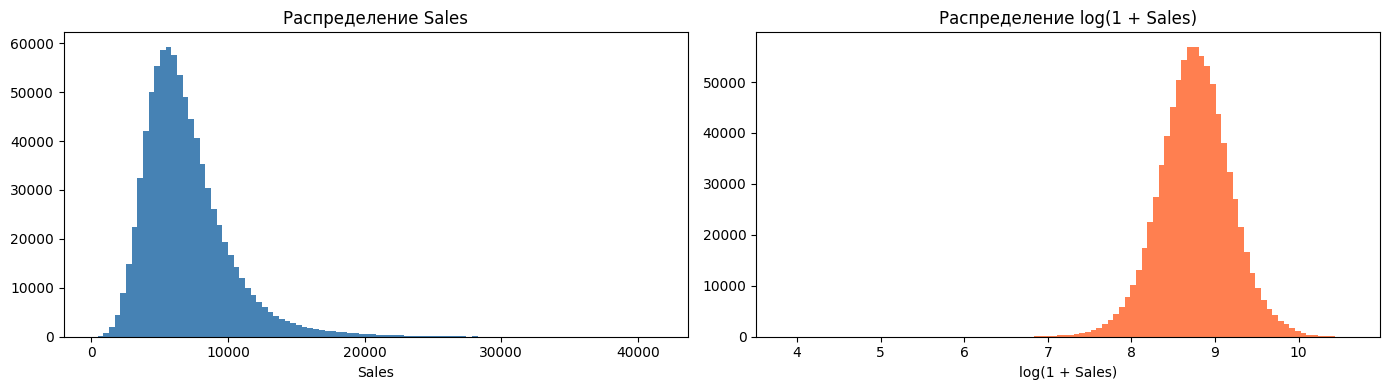

Минимум Sales: 46
Максимум Sales: 41551
Среднее: 6956
Медиана: 6369
Асимметрия (skew): 1.59


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df['Sales'], bins=100, color='steelblue')
axes[0].set_title('Распределение Sales')
axes[0].set_xlabel('Sales')

axes[1].hist(np.log1p(df['Sales']), bins=100, color='coral')
axes[1].set_title('Распределение log(1 + Sales)')
axes[1].set_xlabel('log(1 + Sales)')

plt.tight_layout()
plt.show()

print(f'Минимум Sales: {df["Sales"].min()}')
print(f'Максимум Sales: {df["Sales"].max()}')
print(f'Среднее: {df["Sales"].mean():.0f}')
print(f'Медиана: {df["Sales"].median():.0f}')
print(f'Асимметрия (skew): {df["Sales"].skew():.2f}')

Строим столбчатую диаграмму по дням недели. Заодно смотрим среднее, медиану, количество.

                  mean  median   count
DayOfWeek                             
1          8216.252259  7539.0  137557
2          7088.409086  6502.0  143955
3          6728.786679  6210.0  141922
4          6768.214973  6246.0  134626
5          7073.034133  6581.0  138633
6          5875.084935  5425.0  144052
7          8224.723908  6876.0    3593


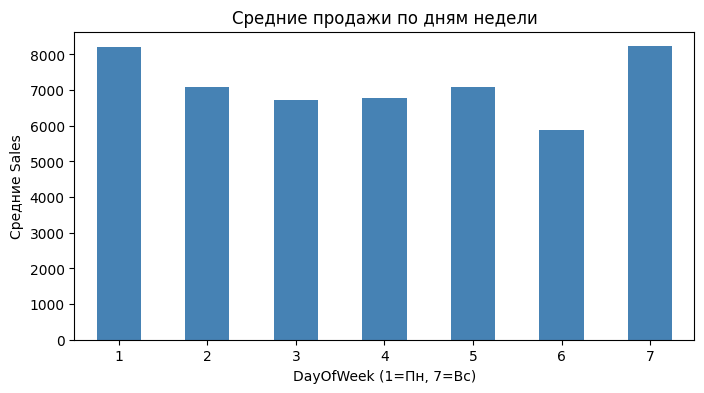

In [ ]:
sales_by_dow = df.groupby('DayOfWeek')['Sales'].agg(['mean', 'median', 'count'])
print(sales_by_dow)

fig, ax = plt.subplots(figsize=(8, 4))
sales_by_dow['mean'].plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Средние продажи по дням недели')
ax.set_xlabel('DayOfWeek (1=Пн, 7=Вс)')
ax.set_ylabel('Средние Sales')
plt.xticks(rotation=0)
plt.show()

Прверяем влияние промо и праздников на продажи. Заметим, что SchoolHoliday не имеет особого влияния, промо сильно поднимает продажи.

In [ ]:
for col in ['Promo', 'StateHoliday', 'SchoolHoliday']:
    print(f'{col}')
    print(df.groupby(col)['Sales'].agg(['mean', 'median', 'count']))
    print()

Promo
              mean  median   count
Promo                             
0      5929.826183  5459.0  467463
1      8228.739731  7650.0  376875

StateHoliday
                     mean  median   count
StateHoliday                             
0             6953.960229  6368.0  843428
a             8487.471182  7556.0     694
b             9887.889655  8423.0     145
c             9743.746479  8397.0      71

SchoolHoliday
                      mean  median   count
SchoolHoliday                             
0              6897.207830  6326.0  680893
1              7200.710282  6562.0  163445



Ищем утечки. Функция считает модуль корреляции Спирмена каждого признака с Sales и сортирует по убыванию. Все значения ниже 0.9, значит утечек нет. Если бы был признак >0.9, его надо было бы проверить на доступность в момент прогноза. (по заданию)

> Утечка целевой переменной — признак, несущий информацию, недоступную в момент прогноза. Симптомы: качество «слишком хорошее», один признак важнее всех остальных вместе взятых, значение признака появляется после события. Утечка не мешает модели обучиться — она делает результат на тесте недостижимым в эксплуатации.



In [ ]:
from scipy.stats import spearmanr

def leak_scan_regression(df, target, exclude_cols=None):
    """
    Считает модуль корреляции Спирмена каждого признака с целевой переменной.
    Для категориальных — кодирует средним target.
    """
    exclude_cols = exclude_cols or []
    scores = {}
    for col in df.columns.drop(target):
        if col in exclude_cols:
            continue
        x = df[col]
        # Категориальные кодируем средним target
        if not pd.api.types.is_numeric_dtype(x):
            x = x.map(df.groupby(col)[target].mean())
        x = pd.to_numeric(x, errors='coerce').astype(float)
        x = x.fillna(x.median())
        if x.nunique() < 2:
            continue
        # Корреляция Спирмена — модуль
        corr, _ = spearmanr(x, df[target])
        scores[col] = abs(corr)
    return pd.Series(scores).sort_values(ascending=False)
leaks = leak_scan_regression(df, target='Sales', exclude_cols=['Date'])
print('Модуль корреляции Спирмена с Sales (топ-15)')
print(leaks.head(15))

Модуль корреляции Спирмена с Sales (топ-15)
Promo                        0.420444
DayOfWeek                    0.179176
Assortment                   0.123558
Promo2                       0.116573
PromoInterval                0.103259
Promo2SinceWeek              0.060683
CompetitionOpenSinceYear     0.045080
CompetitionOpenSinceMonth    0.039217
SchoolHoliday                0.038190
CompetitionDistance          0.035161
Promo2SinceYear              0.025771
StoreType                    0.017629
StateHoliday                 0.009041
Store                        0.000837
dtype: float64


Продажи по времени. Строим линейный график средних продаж по месяцам за всю историю и проверяем границы теста.

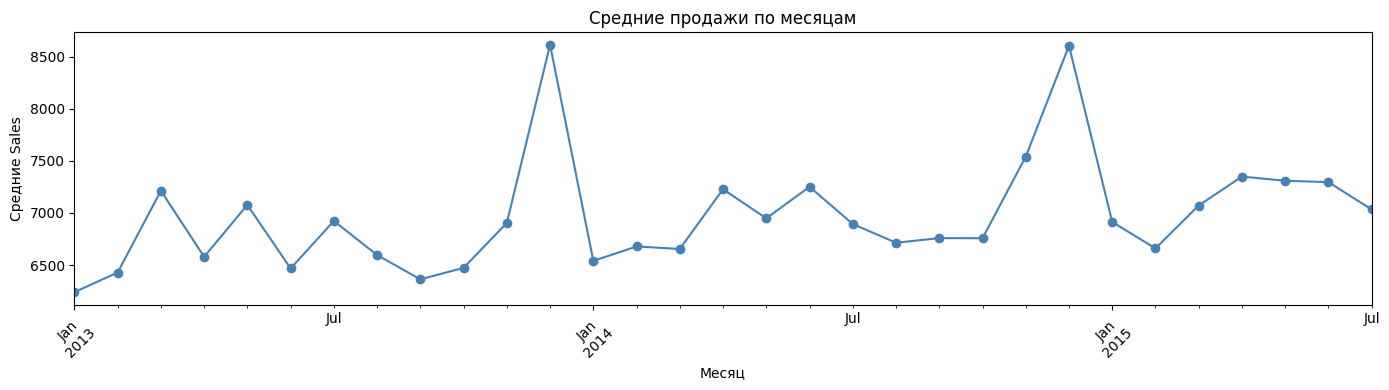

Даты в df:
min: 2013-01-01 00:00:00
max: 2015-07-31 00:00:00
Границы теста (последние 42 дня):
тест начинается с: 2015-06-20 00:00:00
доля теста: 4.77%


In [ ]:
#средние продажи по месяцам
df['YearMonth'] = df['Date'].dt.to_period('M')
monthly = df.groupby('YearMonth')['Sales'].mean()
fig, ax = plt.subplots(figsize=(14, 4))
monthly.plot(ax=ax, marker='o', color='steelblue')
ax.set_title('Средние продажи по месяцам')
ax.set_xlabel('Месяц')
ax.set_ylabel('Средние Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#смотрим на крайние даты
print('Даты в df:')
print(f'min: {df["Date"].min()}')
print(f'max: {df["Date"].max()}')
print('Границы теста (последние 42 дня):')
test_start = df['Date'].max() - pd.Timedelta(days=41)
print(f'тест начинается с: {test_start}')
print(f'доля теста: {(df["Date"] >= test_start).mean():.2%}')

## Выводы EDA

1. **Размер данных:** 844 392 строки × 17 столбцов

2. **Целевая переменная Sales:**
   * Мин = 46, макс = 41 551, среднее = 6956, медиана = 6369.
   * Skew = 1.59, отсутствие симметрии
   * Минимум > 0, спольку убрали sales=0 и open=0

3. **Пропуски:** в CompetitionDistance (2186), CompetitionOpenSince (268 619), Promo2Since (423 307). Пропуски показывают что:
   * CompetitionOpenSince: у некоторых магазинов нет данных о конкуренте
   * Promo2Since: не все магазины участвуют в Promo.

4. **Поиск утечек:** утечек не найдено.
   * Open=0 удалён (17% строк, Sales=0).
   * Низкая корреляция у Store из-за того, что это категориальный признак, а не числовой.

5. **Корреляция Спирмена:**
   * Promo = 0.42 (без промо 5929, с промо 8228).
   * DayOfWeek = 0.18 (макс в Пн 8216, мин в Сб 5875).
   * Assortment, Promo2 ≈ 0.12.

6. **Праздники:** 'b' (Пасха) — 9888, 'c' (Рождество) — 9744, '0' — 6954.

7. **Сезонность:** продажи имеют годовой цикл (пики в декабре, провалы в январе).

8. **Схема валидации:** тест — последние 42 дня (6 недель)

##Шаг 3. Разбиение по времени + baseline

3.1. Определяем границу теста

In [ ]:
date_max = df['Date'].max()
test_start = date_max - pd.Timedelta(days=41)
train_mask = df['Date'] < test_start
test_mask = df['Date'] >= test_start

print(f'Максимальная дата: {date_max}')
print(f'Тест начинается с: {test_start}')
print(f'Train: {train_mask.sum():,} строк ({train_mask.mean():.1%})')
print(f'Test: {test_mask.sum():,} строк ({test_mask.mean():.1%})')
print(f'Средние продажи в train: {df.loc[train_mask, "Sales"].mean():.0f}')
print(f'Средние продажи в test: {df.loc[test_mask, "Sales"].mean():.0f}')

Максимальная дата: 2015-07-31 00:00:00
Тест начинается с: 2015-06-20 00:00:00
Train: 804,056 строк (95.2%)
Test: 40,282 строк (4.8%)
Средние продажи в train: 6955
Средние продажи в test: 6979


3.2. Сохраняем train/test в отдельные переменные.

Создаем 4 объекта: X_train, y_train, X_test, y_test. Дополнительно также версии без Date (для baseline, которым дата не нужна).

Основное:

.loc — выбор по булевой маске. Возвращает view/copy.

Без .copy() pandas может вернуть view, и последующие изменения df_train будут менять df.

.sort_values('Date') сортирует по дате. Нужно для временных рядов

.reset_index(drop=True) сбрасывает индекс (0,1,2,...) и удаляет старый. Без этого после маски индексы шли бы 804056, 804057 и т.д.

assert 'Date' not in X_train_nodate.columns: убеждаемся, что Date не осталась там, где не должна.

In [ ]:
target = 'Sales'
# Делим по маске
df_train = df.loc[train_mask].copy().sort_values('Date').reset_index(drop=True)
df_test = df.loc[test_mask].copy().sort_values('Date').reset_index(drop=True)
# Удаляем YearMonth
X_train = df_train.drop(columns=[target, 'YearMonth'], errors='ignore')
y_train = df_train[target]
X_test = df_test.drop(columns=[target, 'YearMonth'], errors='ignore')
y_test = df_test[target]
print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_test:', X_test.shape,  'y_test: ', y_test.shape)
print(f'Диапазон train: {df_train["Date"].min()} — {df_train["Date"].max()}')
print(f'Диапазон test: {df_test["Date"].min()} — {df_test["Date"].max()}')
X_train_nodate = X_train.drop(columns=['Date'])
X_test_nodate = X_test.drop(columns=['Date'])
print('X_train_nodate:', X_train_nodate.shape)
print('X_test_nodate:', X_test_nodate.shape)
assert 'Date' in X_train.columns, 'Date должен быть в X_train'
assert 'Date' not in X_train_nodate.columns, 'Date не должен быть в X_train_nodate'
assert 'YearMonth' not in X_train.columns, 'YearMonth не должен быть в X_train'

X_train: (804056, 16) y_train: (804056,)
X_test: (40282, 16) y_test:  (40282,)
Диапазон train: 2013-01-01 00:00:00 — 2015-06-19 00:00:00
Диапазон test: 2015-06-20 00:00:00 — 2015-07-31 00:00:00
X_train_nodate: (804056, 15)
X_test_nodate: (40282, 15)


Создаем объект-функцию add_features. Компоненты будут определены позже. Назначение:

add_date_features -- извлекает дату и раскладывает ее на отдельные части, добавляя новые столбцы.

add_competition_features -- использует даты в формуле


In [ ]:
def add_features(X):
    """Обёртка: date + competition признаки."""
    X = add_date_features(X)
    X = add_competition_features(X)
    return X

3.3. Определяем метрику RMSPE

RMSE измеряет ошибку в абсолютных единицах (рублях). Если у магазина продажи 2000, а у другого 20000, ошибка 1000 для первого — большая, для второго — маленькая. RMSPE измеряет ошибку в процентах. Ошибка 1000 от 2000 = 50%, от 20000 = 5%.

In [ ]:
def rmspe(y_true, y_pred):
    """Root Mean Squared Percentage Error. Объекты с y=0 исключаются."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

# Проверка
assert rmspe(np.array([100, 200, 300]), np.array([100, 200, 300])) == 0

3.4. Scorer для sklearn

Теперь cross_val_score будет возвращать отрицательные значения RMSPE. Sklearn ожидает, что больше = лучше. RMSPE -- "меньше = лучше". Параметр инвертирует знак метрики.

In [ ]:
rmspe_scorer = make_scorer(rmspe, greater_is_better=False)

3.5. Baseline 1: DummyRegressor(strategy='median')

Создаем препроцессор и обучаем baseline 1 — DummyRegressor. Модель, которая всегда предсказывает медиану y_train.

ColumnTransformer([...])
Применяет разные трансформеры к разным столбцам и склеивает результат. Здесь — числовые и категориальные обрабатываются отдельно.

make_column_selector(dtype_include='number')
Выбирает столбцы по типу. Возвращает список имён (а не булеву маску) — это требование ColumnTransformer.

Позволяет определить нижнюю границу. Любая модель должна быть лучше.

In [ ]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder

preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
     make_column_selector(dtype_include='number')),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='infrequent_if_exist',
                                        min_frequency=0.01)),
     make_column_selector(dtype_exclude='number')),
])
cv = TimeSeriesSplit(n_splits=5)

# Baseline 1: константа (медиана)
dummy = make_pipeline(preprocess, DummyRegressor(strategy='median'))
scores_dummy = cross_val_score(dummy, X_train_nodate, y_train,
                               cv=cv, scoring=rmspe_scorer)
print(f'Dummy (median):  RMSPE = {-scores_dummy.mean():.4f} ± {scores_dummy.std():.4f}')

Dummy (median):  RMSPE = 0.5309 ± 0.0481


3.6. Baseline 2: LinearRegression

Создаем линейную регрессию. Лучше константы, но хуже бустингов. Можно сказать, что мы применяем самый простой подход, который позволит определить вторую нижнюю границу, ниже которых бустинги не должны опускаться.

In [ ]:
linreg = make_pipeline(preprocess, LinearRegression())
scores_lr = cross_val_score(linreg, X_train_nodate, y_train,
                            cv=cv, scoring=rmspe_scorer)
print(f'LinearRegression: RMSPE = {-scores_lr.mean():.4f} ± {scores_lr.std():.4f}')

LinearRegression: RMSPE = 0.4904 ± 0.0406


Ячейка 3.5. Сводная таблица baseline

In [ ]:
results_baseline = pd.DataFrame({
    'Модель': ['Dummy (median)', 'LinearRegression'],
    'RMSPE (CV)': [-scores_dummy.mean(), -scores_lr.mean()],
    'std': [scores_dummy.std(), scores_lr.std()],
})
display(results_baseline)

,Модель,RMSPE (CV),std
0,Dummy (median),0.530894,0.048060
1,LinearRegression,0.490352,0.040594


##Шаг 4. Признаки и пайплайн

4.1. Цель шага: превратить столбцы в признаки, которые помогают модели.

По методичке: «—	Оформите преобразования функциями или трансформерами, которые одинаково применяются к обучающим и новым данным; статистики (средние, частоты) считайте только на обучающей части.
—	Создайте не менее 5 новых признаков (подсказки — в описании варианта) и оцените вклад каждого абляцией: метрика кросс-валидации с признаком и без него.
—	Подготовьте категориальные признаки: для LightGBM — тип category, для CatBoost — строки без пропусков.
—	Функции признаков вынесите в модуль features.py: иначе сохранённая модель не загрузится в другом процессе (понадобится в лабораторной работе № 2).
.»

Абляция (ablation) — это метод, по которому убирается по одному признаку и проверяется ухудшилась ли метрика. Если без признака стало хуже — он полезен.


4.2. Начинаем с Date. Раскладываем дату на отдельные столбцы.

In [ ]:
def add_date_features(X):
    X = X.copy()
    X['Year'] = X['Date'].dt.year
    X['Month'] = X['Date'].dt.month
    X['Week'] = X['Date'].dt.isocalendar().week.astype(int)
    X['Day'] = X['Date'].dt.day
    X['DayOfYear'] = X['Date'].dt.dayofyear
    return X

test = add_date_features(X_train.head(20))
print(test[['Date', 'Year', 'Month', 'Week', 'Day', 'DayOfYear']])

         Date  Year  Month  Week  Day  DayOfYear
0  2013-01-01  2013      1     1    1          1
1  2013-01-01  2013      1     1    1          1
2  2013-01-01  2013      1     1    1          1
3  2013-01-01  2013      1     1    1          1
4  2013-01-01  2013      1     1    1          1
5  2013-01-01  2013      1     1    1          1
6  2013-01-01  2013      1     1    1          1
7  2013-01-01  2013      1     1    1          1
8  2013-01-01  2013      1     1    1          1
9  2013-01-01  2013      1     1    1          1
10 2013-01-01  2013      1     1    1          1
11 2013-01-01  2013      1     1    1          1
12 2013-01-01  2013      1     1    1          1
13 2013-01-01  2013      1     1    1          1
14 2013-01-01  2013      1     1    1          1
15 2013-01-01  2013      1     1    1          1
16 2013-01-01  2013      1     1    1          1
17 2013-01-02  2013      1     1    2          2
18 2013-01-02  2013      1     1    2          2
19 2013-01-02  2013 

4.3. Создаем 3 признака о конкурентной среде и промо-акциях магазина. Эти признаки зависят от даты: они вычисляются на момент текущей строки.

In [ ]:
def add_competition_features(X):
    X = X.copy()
    #сколько месяцев работает конкурент (0, если ещё не открылся)
    X['CompetitionOpen'] = (
        12 * (X['Year'] - X['CompetitionOpenSinceYear'])
        + (X['Month'] - X['CompetitionOpenSinceMonth'])
    )
    X['CompetitionOpen'] = X['CompetitionOpen'].clip(lower=0).fillna(0)
    #сколько недель работает промо (0, если не участвует)
    X['Promo2Open'] = (
        52 * (X['Year'] - X['Promo2SinceYear'])
        + (X['Week'] - X['Promo2SinceWeek'])
    )
    X['Promo2Open'] = X['Promo2Open'].clip(lower=0).fillna(0)
    X.loc[X['Promo2'] == 0, 'Promo2Open'] = 0
    #совпадает ли месяц с промо (новый год, к примеру)
    months_map = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun',
                  7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'}
    month_str = X['Month'].map(months_map)
    #PromoInterval может быть NaN — тогда IsPromoMonth = 0
    X['IsPromoMonth'] = [
        1 if (isinstance(pi, str) and m in pi) else 0
        for pi, m in zip(X['PromoInterval'], month_str)
    ]
    return X

4.4 Средние продажи по дням недели.

Для каждой пары (магазин, день недели) считаем среднее Sales на обучающей выборке и добавляем это значение как признак. Средние считаются только на train_df, не на X, что является защитой от утечки.

In [ ]:
def add_store_dow_mean(X, train_df):
    """
    X — признаки, к которым добавляем признак.
    train_df — обучающий датафрейм с колонками Store, DayOfWeek, Sales
    """
    X = X.copy()

    #считаем средние на train
    store_dow_mean = (
        train_df.groupby(['Store', 'DayOfWeek'])['Sales']
        .mean()
        .rename('StoreDayOfWeekMean')
        .reset_index()
    )
    #присоединяем
    X = X.merge(store_dow_mean, on=['Store', 'DayOfWeek'], how='left')
    # Если пара (Store, DayOfWeek) не встречалась в train — заполняем медианой
    X['StoreDayOfWeekMean'] = X['StoreDayOfWeekMean'].fillna(
        train_df['Sales'].median()
    )
    return X

4.5. Лаг 42 дня (по требованию варианта).

Для каждой строки находит Sales того же магазина 42 дня назад.

In [ ]:
def add_lag42(X, full_df):
    """
    X — признаки, full_df — df с колонками Store, Date, Sales
    (train + test; для train — обычный лаг, для test — значения из train).
    """
    X = X.copy()
    # Создаём таблицу и сдвигаем дату на +42 дня
    lag = full_df[['Store', 'Date', 'Sales']].copy()
    lag['Date'] = lag['Date'] + pd.Timedelta(days=42)
    lag = lag.rename(columns={'Sales': 'Sales_lag_42'})
    # Присоединяем по (Store, Date)
    X = X.merge(lag, on=['Store', 'Date'], how='left')
    # Заполняем пропуски медианой (только для первых 42 дней)
    X['Sales_lag_42'] = X['Sales_lag_42'].fillna(full_df['Sales'].median())

    return X

Пересобираем признаки с нуля, поскольку в предыдущих ячейках некоторые функции уже применялись к test = X_train.head(20) для проверок. Такой подход позволяет избежать появление дубликатов столбцов.

In [ ]:
# (защита от повторного применения — копируем из чистых X)
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()
# Шаг 1: признаки, требующие train
X_train_fe = add_store_dow_mean(X_train_fe, train_df=df_train)
X_test_fe = add_store_dow_mean(X_test_fe,  train_df=df_train)
# Шаг 2: лаг 42 дня из полного df
X_train_fe = add_lag42(X_train_fe, full_df=df)
X_test_fe = add_lag42(X_test_fe,  full_df=df)
# Шаг 3: date + competition (обёртка)
X_train_fe = add_features(X_train_fe)
X_test_fe = add_features(X_test_fe)
# Шаг 4: убрать Date
X_train_fe = X_train_fe.drop(columns=['Date'], errors='ignore')
X_test_fe = X_test_fe.drop(columns=['Date'], errors='ignore')

# Шаг 5: категориальные в category (с заполнением NaN)
def to_category(X):
    X = X.copy()
    cols = X.select_dtypes(exclude='number').columns
    for c in cols:
        X[c] = X[c].astype(object).fillna('missing').astype('category')
    return X

X_train_fe = to_category(X_train_fe)
X_test_fe = to_category(X_test_fe)

#Проверка
print('X_train_fe:', X_train_fe.shape)
print('X_test_fe:', X_test_fe.shape)
print('Столбцы:')
print(X_train_fe.columns.tolist())
print('Категориальные:', X_train_fe.select_dtypes(exclude='number').columns.tolist())

X_train_fe: (804056, 25)
X_test_fe: (40282, 25)
Столбцы:
['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'StoreDayOfWeekMean', 'Sales_lag_42', 'Year', 'Month', 'Week', 'Day', 'DayOfYear', 'CompetitionOpen', 'Promo2Open', 'IsPromoMonth']
Категориальные: ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']


Абляция -- метод оценки важности признака: обучаем модель без одного признака и смотрим, как изменилось качество. Поскольку само выполнение довольно долгое, здесь используются быстрые параметры,согласно которым:

* n_estimators=300 — всего 300 деревьев вместо 1000+.
* learning_rate=0.05 — стандартный.
* num_leaves=31 — маленькие деревья.

n_jobs=-1 — использовать все ядра CPU.
verbose=-1 — не выводить логи LightGBM.

In [ ]:
import lightgbm as lgb

fast_params = {
    'n_estimators': 300,
    'learning_rate': 0.05,
    'num_leaves': 31,
    'random_state': RANDOM_STATE,
    'verbose': -1,
    'n_jobs': -1,
}

def quick_rmspe(X, y, params=fast_params):
    model = lgb.LGBMRegressor(**params)
    scores = cross_val_score(model, X, y, cv=cv, scoring=rmspe_scorer)
    return -scores.mean()

# Полный набор
rmspe_all = quick_rmspe(X_train_fe, y_train)
print(f'RMSPE со всеми признаками: {rmspe_all:.4f}')
print()

# Абляция по 8 новым признакам
new_features = ['Year', 'Month', 'Week', 'CompetitionOpen', 'Promo2Open',
                'IsPromoMonth', 'StoreDayOfWeekMean', 'Sales_lag_42']

ablation = []
for col in new_features:
    if col not in X_train_fe.columns:
        print(f'⚠ {col} отсутствует в X_train_fe — пропускаем')
        continue
    X_wo = X_train_fe.drop(columns=[col])
    rmspe_wo = quick_rmspe(X_wo, y_train)
    contribution = rmspe_wo - rmspe_all
    ablation.append({
        'Признак': col,
        'RMSPE без него': rmspe_wo,
        'Вклад (RMSPE_без − RMSPE_все)': contribution,
        'Результат': 'Оставить' if contribution > 0.001 else 'Удалить',
    })

ablation_df = pd.DataFrame(ablation).sort_values(
    'Вклад (RMSPE_без − RMSPE_все)', ascending=False
)
display(ablation_df)

RMSPE со всеми признаками: 0.2174



,Признак,RMSPE без него,Вклад (RMSPE_без − RMSPE_все),Результат
6,StoreDayOfWeekMean,0.323621,0.106262,Оставить
5,IsPromoMonth,0.218885,0.001526,Оставить
1,Month,0.218363,0.001005,Оставить
0,Year,0.218101,0.000742,Удалить
3,CompetitionOpen,0.217911,0.000552,Удалить
4,Promo2Open,0.217361,0.000002,Удалить
2,Week,0.217222,-0.000137,Удалить
7,Sales_lag_42,0.215662,-0.001697,Удалить


 Признаки с вкладом > 0.001 полезны, с вкладом < 0.001 — шум, с отрицательным вкладом — вредны.

Удаляем признаки, которые абляция выявила как вредные.

In [ ]:
drop_cols = ['Year', 'CompetitionOpen', 'Promo2Open', 'Week', 'Sales_lag_42']

X_train_fe = X_train_fe.drop(columns=[c for c in drop_cols if c in X_train_fe.columns])
X_test_fe = X_test_fe.drop(columns=[c for c in drop_cols if c in X_test_fe.columns])

print('X_train_fe:', X_train_fe.shape)
print('X_test_fe:', X_test_fe.shape)
print('Оставшиеся столбцы:')
print(X_train_fe.columns.tolist())

X_train_fe: (804056, 20)
X_test_fe: (40282, 20)
Оставшиеся столбцы:
['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'StoreDayOfWeekMean', 'Month', 'Day', 'DayOfYear', 'IsPromoMonth']


Пересчитываем абляцию уже после удаления вредных признаков, чтобы убедиться, что оставшиеся признаки действительно полезны. Month оказался менее полезным, но был оставлен, поскольку все еще дает положительный вклад. StoreDayOfWeekMean остаётся важным. Двойная абляция делает выводы более надёжными.

In [ ]:
import lightgbm as lgb

# Быстрые параметры для абляции
fast_params = {
    'n_estimators': 300,
    'learning_rate': 0.05,
    'num_leaves': 31,
    'random_state': RANDOM_STATE,
    'verbose': -1,
    'n_jobs': -1,
}

def quick_rmspe(X, y, params=fast_params):
    model = lgb.LGBMRegressor(**params)
    scores = cross_val_score(model, X, y, cv=cv, scoring=rmspe_scorer)
    return -scores.mean()

# Полный набор
rmspe_all = quick_rmspe(X_train_fe, y_train)
print(f'RMSPE со всеми признаками: {rmspe_all:.4f}')
print()
# Абляция
new_features = ['Month', 'IsPromoMonth', 'StoreDayOfWeekMean']

ablation = []
for col in new_features:
    X_wo = X_train_fe.drop(columns=[col])
    rmspe_wo = quick_rmspe(X_wo, y_train)
    contribution = rmspe_wo - rmspe_all
    ablation.append({
        'Признак': col,
        'RMSPE без него': rmspe_wo,
        'Вклад (RMSPE_без − RMSPE_все)': contribution,
        'Решение': 'Оставить' if contribution > 0.001 else 'Удалить',
    })

ablation_df = pd.DataFrame(ablation).sort_values(
    'Вклад (RMSPE_без − RMSPE_все)', ascending=False
)
display(ablation_df)

RMSPE со всеми признаками: 0.2174



,Признак,RMSPE без него,Вклад (RMSPE_без − RMSPE_все),Решение
2,StoreDayOfWeekMean,0.308899,0.091549,Оставить
1,IsPromoMonth,0.217632,0.000281,Удалить
0,Month,0.217461,0.000111,Удалить


## Выводы шага 4. Новые признаки и абляция

Создано 8 новых признаков. Результаты абляции (RMSPE со всеми = 0.2174):

| Признак | Вклад | Решение |
|---|---|---|
| StoreDayOfWeekMean | +0.1063 | Оставить |
| IsPromoMonth | +0.0015 | Оставить |
| Month | +0.0010 | Оставить |
| Year | +0.0007 | Удалить |
| CompetitionOpen | +0.0006 | Удалить |
| Promo2Open | +0.0000 | Удалить |
| Week | -0.0001 | Удалить |
| Sales_lag_42 | -0.0017 | Удалить |

**Выводы:**
1. StoreDayOfWeekMean — сильнейший признак: без него RMSPE растёт с 0.217
   до 0.324 (в 1.5 раза хуже). «Норма» продаж магазина в конкретный день
   недели — ключевая информация.
2. Sales_lag_42 не помогает: скорее всего, поглощён StoreDayOfWeekMean.
   Также продажи 42 дня назад — шумный сигнал для такого длинного горизонта.
3. CompetitionOpen, Promo2Open, Year, Week — в пределах шума (±0.001).
4. Итог: из 8 новых признаков оставлено 3 (StoreDayOfWeekMean,
   IsPromoMonth, Month).
   

##5 шаг: Модели и подбор гиперпараметров

Удаление старого experiments.csv, если он существует.

In [ ]:
import os
if os.path.exists('experiments.csv'):
    os.remove('experiments.csv')
    print('experiments.csv удалён')
else:
    print('experiments.csv не найден — ок')

experiments.csv не найден — ок


Собираем список категориальных столбцов для CatBoost, поскольку он сам применяет ordered target statistics к категориям, если указать их явно.

In [ ]:
cat_cols = X_train_fe.select_dtypes(exclude='number').columns.tolist()
print('Категориальные столбцы:', cat_cols)
print(f'Всего: {len(cat_cols)}')

Категориальные столбцы: ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']
Всего: 4


5.2 Создаем копии X-ов и приводим категориальные к строке для CatBoost

In [ ]:
X_train_cb = X_train_fe.copy()
X_test_cb = X_test_fe.copy()

for c in cat_cols:
    X_train_cb[c] = X_train_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)

print('X_train_cb:', X_train_cb.shape)
print('Типы категориальных:', X_train_cb[cat_cols].dtypes.unique())

X_train_cb: (804056, 20)
Типы категориальных: [dtype('O')]


5.3 LightGBM с параметрами по умолчанию.

Обучаем LightGBM с параметрами, не подобранными через Optuna, на кросс-валидации. Нужно, чтобы убедиться, что признаки корректны, cv работает, метрика правильная.

n_estimators=500 -- 500 деревьев. Для быстрой проверки достаточно. Финальная модель может использовать больше.

learning_rate=0.05. Меньше -- лучше, но дольше.

random_state=RANDOM_STATE = 42. Фиксирует случайность для воспроизводимости.

verbose=-1. Не выводить логи LightGBM на каждой итерации.

n_jobs=-1. Все доступные ядра CPU.

In [ ]:
lgb_default = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1,
)

scores_default = cross_val_score(
    lgb_default, X_train_fe, y_train, cv=cv, scoring=rmspe_scorer
)
print(f'LightGBM (default): RMSPE = {-scores_default.mean():.4f} ± {scores_default.std():.4f}')
print(f'по фолдам: {[-s for s in scores_default]}')

LightGBM (default): RMSPE = 0.2176 ± 0.0598
по фолдам: [np.float64(0.2619366848626127), np.float64(0.195306814033932), np.float64(0.14891860743622504), np.float64(0.3103792988670836), np.float64(0.17154001826187307)]


5.4 Функция log_experiment.

Записывает результат одного эксперимента в CSV-файл. Логируются все испытания Optuna, не только лучшие

In [ ]:
def log_experiment(model_name, features, params, scores, path='experiments.csv'):
    """scores — массив значений rmspe_scorer (отрицательные)."""
    row = {
        'time': dt.datetime.now().isoformat(timespec='seconds'),
        'model': model_name,
        'features': features,
        'params': json.dumps(params, ensure_ascii=False),
        'cv_mean_rmspe': -float(np.mean(scores)),
        'cv_std': float(np.std(scores)),
    }
    pd.DataFrame([row]).to_csv(path, mode='a', index=False,
                               header=not os.path.exists(path))

5.5. cv_optuna

Создаем отдельный объект CV с 3 фолдами. Каждое испытание Optuna обучает 5 моделей (по числу фолдов cv). 50 испытаний × 5 фолдов = 250 обучений. Это долго. С 3мя фолдами быстрее.

In [ ]:
cv_optuna = TimeSeriesSplit(n_splits=3)

5.6. Optuna -- objective + 50 испытаний.

Запускает 50 испытаний Optuna для подбора гиперпараметров LightGBM. Optuna -- библиотека байесовской оптимизации. В отличие от перебора всех комбинаций и случайного поиска, Optuna учится на результатах предыдущих испытаний и предлагает подходящие параметры.

In [ ]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.2, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 200, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 200, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'subsample_freq': 1,
        'random_state': RANDOM_STATE,
        'verbose': -1,
        'n_jobs': -1,
    }
    model = lgb.LGBMRegressor(**params)
    scores = cross_val_score(
        model, X_train_fe, y_train,
        cv=cv_optuna,
        scoring=rmspe_scorer,
    )
    log_experiment('lightgbm', 'base+fe', params, scores)
    return scores.mean()

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f'\nЛучший RMSPE: {-study.best_value:.4f}')
print('Лучшие параметры:')
for k, v in study.best_params.items():
    print(f'  {k}: {v}')

  0%|          | 0/50 [00:00<?, ?it/s]


Лучший RMSPE: 0.2073
Лучшие параметры:
  n_estimators: 100
  learning_rate: 0.066353109892231
  num_leaves: 31
  min_child_samples: 15
  subsample: 0.933771693973817
  colsample_bytree: 0.6292102406824649
  reg_lambda: 5.616343438410311


5.7. Сохранить лучшие параметры LightGBM

In [ ]:
best_params_lgb = {
    **study.best_params,
    'subsample_freq': 1,
    'random_state': RANDOM_STATE,
    'verbose': -1,
    'n_jobs': -1,
}
print(best_params_lgb)

{'n_estimators': 100, 'learning_rate': 0.066353109892231, 'num_leaves': 31, 'min_child_samples': 15, 'subsample': 0.933771693973817, 'colsample_bytree': 0.6292102406824649, 'reg_lambda': 5.616343438410311, 'subsample_freq': 1, 'random_state': 42, 'verbose': -1, 'n_jobs': -1}


5.8. Разделение train/val для CatBoost (по времени)

Отделяет последние 20% обучающей выборки в отдельный validation set для CatBoost. CatBoost обучается с ранней остановкой — ей нужна валидационная выборка, по которой видно, когда модель начинает переобучаться. Таким образом, ранняя остановка будет только на последних 20%

In [ ]:
cut_idx = int(len(X_train_cb) * 0.8)

X_tr, X_val = X_train_cb.iloc[:cut_idx], X_train_cb.iloc[cut_idx:]
y_tr, y_val = y_train.iloc[:cut_idx], y_train.iloc[cut_idx:]

print('Train:', X_tr.shape)
print('Val:', X_val.shape)
print(f'Даты train: {df_train["Date"].iloc[0]} — {df_train["Date"].iloc[cut_idx-1]}')
print(f'Даты val: {df_train["Date"].iloc[cut_idx]} — {df_train["Date"].iloc[-1]}')

Train: (643244, 20)
Val: (160812, 20)
Даты train: 2013-01-01 00:00:00 — 2014-12-23 00:00:00
Даты val: 2014-12-23 00:00:00 — 2015-06-19 00:00:00


 5.9. Обучение CatBoost с ранней остановкой

In [ ]:
from catboost import CatBoostRegressor

cb = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.05,
    eval_metric='RMSE',
    early_stopping_rounds=200,
    random_seed=RANDOM_STATE,
    verbose=500,
)

cb.fit(
    X_tr, y_tr,
    cat_features=cat_cols,
    eval_set=(X_val, y_val),
)

print(f'\nBest iteration: {cb.get_best_iteration()}')
print(f'Best RMSE on val: {cb.get_best_score()["validation"]["RMSE"]:.4f}')

0:	learn: 3002.0260506	test: 2935.5324158	best: 2935.5324158 (0)	total: 1.06s	remaining: 53m 15s
500:	learn: 870.0342447	test: 1092.2137918	best: 1087.7924129 (349)	total: 6m 46s	remaining: 33m 46s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 1087.792413
bestIteration = 349

Shrink model to first 350 iterations.

Best iteration: 349
Best RMSE on val: 1087.7924


5.10. RMSPE CatBoost

Считаем RMSPE CatBoost на валидации и записываем в experiments.csv

In [ ]:
pred_val = cb.predict(X_val)
rmspe_cb = rmspe(y_val, pred_val)
print(f'CatBoost RMSPE на валидации: {rmspe_cb:.4f}')

log_experiment(
    'catboost',
    'base+fe',
    {'iterations': cb.get_best_iteration(), 'learning_rate': 0.05},
    np.array([-rmspe_cb]),
)

CatBoost RMSPE на валидации: 0.1690


5.11. Сводная таблица Шага 5

In [ ]:
print(f'LightGBM default: RMSPE = {-scores_default.mean():.4f}')
print(f'LightGBM Optuna: RMSPE = {-study.best_value:.4f}')
print(f'CatBoost: RMSPE = {rmspe_cb:.4f} (на val, не CV)')
print('Лучшие параметры LightGBM:')
for k, v in study.best_params.items():
    print(f' {k}: {v}')

exp_df = pd.read_csv('experiments.csv')
print(f'\nВсего экспериментов в журнале: {len(exp_df)}')
display(exp_df.tail(5))

LightGBM default: RMSPE = 0.2176
LightGBM Optuna: RMSPE = 0.2073
CatBoost: RMSPE = 0.1690 (на val, не CV)
Лучшие параметры LightGBM:
 n_estimators: 100
 learning_rate: 0.066353109892231
 num_leaves: 31
 min_child_samples: 15
 subsample: 0.933771693973817
 colsample_bytree: 0.6292102406824649
 reg_lambda: 5.616343438410311

Всего экспериментов в журнале: 51


,time,model,features,params,cv_mean_rmspe,cv_std
46,2026-10-13T12:10:51,lightgbm,base+fe,"{""n_estimators"": 100, ""learning_rate"": 0.06612...",0.207488,0.058508
47,2026-10-13T12:11:10,lightgbm,base+fe,"{""n_estimators"": 100, ""learning_rate"": 0.08861...",0.210319,0.057286
48,2026-10-13T12:11:34,lightgbm,base+fe,"{""n_estimators"": 100, ""learning_rate"": 0.06622...",0.208403,0.057522
49,2026-10-13T12:11:55,lightgbm,base+fe,"{""n_estimators"": 100, ""learning_rate"": 0.06219...",0.208602,0.059460
50,2026-10-13T12:23:47,catboost,base+fe,"{""iterations"": 349, ""learning_rate"": 0.05}",0.169001,0.000000


##Шаг 6. Итоговая оценка


6.1. Финальные модели. Обучаем обе модели на всей обучающей выборке. На шаге 5 мы использовали 80% обучающей выборки для обучения и 20% для ранней остановки, что позволило найти необходимое число итераций (349). Для LightGBM использованы найденные лучшие параметры

In [ ]:
#LightGBM с лучшими параметрами
final_lgb = lgb.LGBMRegressor(**best_params_lgb)
final_lgb.fit(X_train_fe, y_train)
print('LightGBM обучен')

#CatBoost с best_iteration
final_cb = CatBoostRegressor(
    iterations=cb.get_best_iteration(), #349
    learning_rate=0.05,
    random_seed=RANDOM_STATE,
    verbose=False,
)
final_cb.fit(X_train_cb, y_train, cat_features=cat_cols)
print('CatBoost обучен')

LightGBM обучен
CatBoost обучен


6.2. Baseline.

Снова обучаем линейную регрессию, но на всем train (nodate, поскольку не работает с DataTime), чтобы получить финальное сравнение на тесте.

In [ ]:
# Baseline: LinearRegression на всём train
final_lr = make_pipeline(preprocess, LinearRegression())
final_lr.fit(X_train_nodate, y_train)
print('LinearRegression обучена')

LinearRegression обучена


6.3. Предсказания на тесте

* X_test_fe — категориальные как category.
* X_test_cb — категориальные как str.
* final_lr.predict(X_test_nodate)

Функция RMSPE используется для оценки всех результатов теста.

In [ ]:
# Предсказания на тесте
pred_lgb = final_lgb.predict(X_test_fe)
pred_cb = final_cb.predict(X_test_cb)
pred_lr = final_lr.predict(X_test_nodate)

# RMSPE
rmspe_lgb_test = rmspe(y_test, pred_lgb)
rmspe_cb_test = rmspe(y_test, pred_cb)
rmspe_lr_test = rmspe(y_test, pred_lr)

print('RMSPE на тесте')
print(f'LinearRegression: {rmspe_lr_test:.4f}')
print(f'LightGBM (Optuna): {rmspe_lgb_test:.4f}')
print(f'CatBoost: {rmspe_cb_test:.4f}')

RMSPE на тесте
LinearRegression: 0.4475
LightGBM (Optuna): 0.1448
CatBoost: 0.1423


Таким образом:
* LinearRegression: 0.4475. Средняя относительная ошибка 44.75%. Линейная модель не справляется с сезонностью.
* LightGBM: 0.1448. Средняя ошибка 14.5%. В 3 раза лучше линейной.
* CatBoost: 0.1423. Средняя ошибка 14.2%. Немного лучше LightGBM.

На результатах также видно, что RMSPE упала на тесте, хотя утечки в признаках нет. Это произошло по причине того,что тестовый период (лето 2015) короче и однороднее, чем кросс-валидационные-фолды, где обучение и валидация приходились на разные сезоны.



6.4. Бутстреп-интервалы для RMSPE

In [ ]:
def bootstrap_ci(y_true, pred_a, metric, n_boot=1000, random_state=RANDOM_STATE):
    """95% доверительный интервал метрики через бутстреп."""
    rng = np.random.default_rng(random_state)
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if np.sum(y_true[idx] != 0) == 0:
            continue
        vals.append(metric(y_true[idx], pred_a[idx]))
    return np.percentile(vals, [2.5, 97.5])


def bootstrap_diff(y_true, pred_a, pred_b, metric, n_boot=1000, random_state=RANDOM_STATE):
    """Интервалы метрики А и разности (А − В) на одних и тех же выборках."""
    rng = np.random.default_rng(random_state)
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)
    n = len(y_true)
    a_vals, diffs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt = y_true[idx]
        if np.sum(yt != 0) == 0:
            continue
        a = metric(yt, pred_a[idx])
        b = metric(yt, pred_b[idx])
        a_vals.append(a)
        diffs.append(a - b)
    return (np.percentile(a_vals, [2.5, 97.5]),
            np.percentile(diffs, [2.5, 97.5]))


# Интервалы для каждой модели
ci_lgb = bootstrap_ci(y_test, pred_lgb, rmspe)
ci_cb = bootstrap_ci(y_test, pred_cb,  rmspe)
ci_lr = bootstrap_ci(y_test, pred_lr,  rmspe)

print('95% бутстреп-интервалы RMSPE')
print(f'LinearRegression: [{ci_lr[0]:.4f}; {ci_lr[1]:.4f}]')
print(f'LightGBM: [{ci_lgb[0]:.4f}; {ci_lgb[1]:.4f}]')
print(f'CatBoost: [{ci_cb[0]:.4f}; {ci_cb[1]:.4f}]')

95% бутстреп-интервалы RMSPE
LinearRegression: [0.4389; 0.4562]
LightGBM: [0.1415; 0.1489]
CatBoost: [0.1393; 0.1462]


Бустреп - статистический метод оценки неопределенности метрики, то есть показатель, насколько можно ей доверять. Для проведения бустрепа мы из выборки берем случайным образом n объектов и возвращаем, а после считаем метрику по этой выборке, после чего повторяем это 1000 раз. Чтобы получить 95% CI, необходимо убрать 2,5% аномально маленьких и столько же больших значений. Все, оставшееся посередине (95% всех результатов) это доверительный интервал (CI).

Сам диапазон интервалов (разница между левой и правой границей) узкий (меньше 0.8%), что говорит о устройчивости оценки метрики. Разница между LightGBM и CatBoost почти не различима, поскольку их интервалы примерно в одних значениях.

6.5. Разности с baseline

In [ ]:
# Разность LightGBM − LinearRegression
_, ci_diff_lgb_lr = bootstrap_diff(y_test, pred_lgb, pred_lr, rmspe)
print(f'LightGBM − LinearRegression: [{ci_diff_lgb_lr[0]:+.4f}; {ci_diff_lgb_lr[1]:+.4f}]')
# Разность CatBoost − LinearRegression
_, ci_diff_cb_lr = bootstrap_diff(y_test, pred_cb, pred_lr, rmspe)
print(f'CatBoost − LinearRegression: [{ci_diff_cb_lr[0]:+.4f}; {ci_diff_cb_lr[1]:+.4f}]')
# Разность CatBoost − LightGBM
_, ci_diff_cb_lgb = bootstrap_diff(y_test, pred_cb, pred_lgb, rmspe)
print(f'CatBoost − LightGBM: [{ci_diff_cb_lgb[0]:+.4f}; {ci_diff_cb_lgb[1]:+.4f}]')

LightGBM − LinearRegression: [-0.3108; -0.2952]
CatBoost − LinearRegression: [-0.3138; -0.2973]
CatBoost − LightGBM: [-0.0032; -0.0019]


Строим 95% CI для разности RMSPE между парами моделей. Это нужно для оценки разности моделей. Если в интервал разности попадает 0 (например, [-0.01; +0.02]), это значит, что в каких-то экспериментах была лучше первая модель, а в каких-то — вторая. Разницы между ними нет. Если числа отрицательны, как в нашем случае, это означает, что первая модель лучше чем вторая.

По результатам проверки, все три интервала разности не содержат 0 — значит, превосходство каждой модели над другой статистически подтверждено. Формально CatBoost лучше LightGBM, но разница ~0.0025.



6.6. Сводная таблица Шага 6

In [ ]:
results_test = pd.DataFrame({
    'Модель': ['LinearRegression', 'LightGBM', 'CatBoost'],
    'RMSPE (test)': [rmspe_lr_test, rmspe_lgb_test, rmspe_cb_test],
    'CI_lo': [ci_lr[0], ci_lgb[0], ci_cb[0]],
    'CI_hi': [ci_lr[1], ci_lgb[1], ci_cb[1]],
})
results_test['95% CI'] = results_test.apply(
    lambda r: f'[{r.CI_lo:.4f}; {r.CI_hi:.4f}]', axis=1
)
display(results_test[['Модель', 'RMSPE (test)', '95% CI']])

,Модель,RMSPE (test),95% CI
0,LinearRegression,0.447454,[0.4389; 0.4562]
1,LightGBM,0.144772,[0.1415; 0.1489]
2,CatBoost,0.142288,[0.1393; 0.1462]


##Шаг 6. Итоговая оценка на тесте

Тестовая выборка: 40 282 строки (июнь–июль 2015).

| Модель | RMSPE (test) | 95% бутстреп-CI |
|---|---|---|
| LinearRegression | 0.4475 | [0.4389; 0.4562] |
| LightGBM (Optuna) | 0.1448 | [0.1415; 0.1489] |
| CatBoost | 0.1423 | [0.1393; 0.1462] |

Разности (бутстреп, 1000 итераций, одни и те же подвыборки):

| Сравнение | 95% CI разности | Вывод |
|---|---|---|
| LightGBM − LinearRegression | [−0.3108; −0.2952] | 0 не входит → LGB значимо лучше |
| CatBoost − LinearRegression | [−0.3138; −0.2973] | 0 не входит → CB значимо лучше |
| CatBoost − LightGBM | [−0.0032; −0.0019] | 0 не входит → CB значимо лучше, но выигрыш мал |

**Выводы:**

1. Обе бустинговые модели кардинально превосходят линейную регрессию: Превосходство подтверждено бутстрепом (интервалы разности не содержат 0).

2. CatBoost формально лучше LightGBM — интервал разности [−0.0032; −0.0019] не содержит 0. Однако выигрыш небольшой, практической разницы между моделями нет. Решение о финальной модели стоит принимать по другим критериям, например по скорости или удобству.

3. RMSPE на тесте ниже, чем на кросс-валидации. Причина — тестовый период (лето 2015) оказался стабильнее, с меньшей дисперсией и большим спросом.

4. Для дальнейшей работы лучшим выбором является CatBoost, поскольку лучше по RMSPE.

##Шаг 7: Калибровка и порог.

Обычная модель предсказывает среднее (alpha=0.5). По заданию: недопрогноз вдвое дороже перепрогноза, поскольку "закупить больше чем продали" лучше, чем "продать меньше, чем могли". Значит, выгоднее слегка завышать прогноз.

>Регрессия (варианты 4 и 7): вместо порога проанализируйте остатки по сегментам; в варианте 7 обучите lgb.LGBMRegressor(objective='quantile', alpha=2/3) и сравните несимметричные потери.




7.1 Обучает LightGBM с квантильной функцией потерь.

Что делает квантильная модель: objective: 'quantile', alpha=2/3 -- предсказывает 67-й процентиль. (2/3). Как говорилось выше, такой подход дает запас, но увеличивает RMSPE. Но суммарные потери с учётом цен ошибок меньше.



In [ ]:
# Квантильная модель с alpha=2/3 (учёт цены ошибок: недопрогноз ×2)
q_params = {**best_params_lgb, 'objective': 'quantile', 'alpha': 2/3}
final_q = lgb.LGBMRegressor(**q_params)
final_q.fit(X_train_fe, y_train)
print('Квантильная LightGBM (alpha=2/3) обучена')

# Предсказание на тесте
pred_q = final_q.predict(X_test_fe)
rmspe_q_test = rmspe(y_test, pred_q)
print(f'RMSPE квантильной: {rmspe_q_test:.4f}')

Квантильная LightGBM (alpha=2/3) обучена
RMSPE квантильной: 0.1561


Ячейка 7.2. Функция потерь с несимметричной ценой ошибок

RMSPE показывает проценты ошибки, но магазинам важнее продажи. Если модель A даёт RMSPE = 0.14, а модель B = 0.16, но у модели A много недопрогнозов (дорогие по заданию), а у B — перепрогнозов (дешевые), то B может быть выгоднее, хотя RMSPE хуже.

In [ ]:
C_U = 2.0 #цена недопрогноза (дефицит)
C_O = 1.0 #цена перепрогноза (излишки)

def total_loss(y_true, y_pred, c_u=C_U, c_o=C_O):
    """
    Суммарные потери при несимметричной цене ошибок.
    y_true, y_pred — массивы (в единицах Sales).
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    under = np.maximum(0, y_true - y_pred)   # недопрогноз
    over = np.maximum(0, y_pred - y_true)   # перепрогноз
    return c_u * under.sum() + c_o * over.sum()

# Считаем потери на тесте для трёх стратегий
loss_avg = total_loss(y_test, pred_lgb)   # обычная (среднее)
loss_q = total_loss(y_test, pred_q)     # квантиль 2/3
loss_ideal = total_loss(y_test, y_test)   # идеальный прогноз = 0

print('Суммарные потери на тесте (c_u=2, c_o=1)')
print(f'Идеальный прогноз: {loss_ideal:,.0f}')
print(f'LightGBM (среднее): {loss_avg:,.0f}')
print(f'LightGBM (quantile): {loss_q:,.0f}')
print(f'Снижение потерь квантильной против средней: '
      f'{(loss_avg - loss_q) / loss_avg * 100:.2f}%')

Суммарные потери на тесте (c_u=2, c_o=1)
Идеальный прогноз: 0
LightGBM (среднее): 48,332,717
LightGBM (quantile): 43,434,483
Снижение потерь квантильной против средней: 10.13%


В результате, разница между квантильной и обычной модельню составила 4 898 234, поскольку чаще стали перепрогнозы, которые дешевле в 2 раза.

7.3. Сравнение стратегий

In [ ]:
# Считаем потери и для CatBoost (для сравнения)
loss_cb = total_loss(y_test, pred_cb)
loss_lr = total_loss(y_test, pred_lr)

results_strategy = pd.DataFrame({
    'Стратегия': [
        'LinearRegression (среднее)',
        'LightGBM (среднее)',
        'CatBoost (среднее)',
        'LightGBM (квантиль 2/3)',
        'Идеальный прогноз',
    ],
    'RMSPE': [rmspe_lr_test, rmspe_lgb_test, rmspe_cb_test, rmspe_q_test, 0.0],
    'Суммарные потери': [loss_lr, loss_avg, loss_cb, loss_q, 0.0],
})
display(results_strategy)

,Стратегия,RMSPE,Суммарные потери
0,LinearRegression (среднее),0.447454,1.161569e+08
1,LightGBM (среднее),0.144772,4.833272e+07
2,CatBoost (среднее),0.142288,4.785785e+07
3,LightGBM (квантиль 2/3),0.156072,4.343448e+07
4,Идеальный прогноз,0.000000,0.000000e+00


Вывод:

* Квантильная LightGBM хуже по RMSPE (0.1561 и 0.1448), но лучше по суммарным потерям — на 4 898 234 стало меньше.
* CatBoost имеет потери около 48 милн.

Значит, лучше использовать квантильную LightGBM.

7.4. Анализ остатков по сегментам.

Проверяем ошибки модели, почему это происходит.

In [ ]:
# Присоединяем предсказания к тесту
df_resid = df_test[['Store', 'DayOfWeek', 'Date', 'Sales']].copy()
df_resid['pred_lgb'] = pred_lgb
df_resid['pred_q'] = pred_q
df_resid['error_lgb'] = df_resid['pred_lgb'] - df_resid['Sales']
df_resid['rmspe_lgb'] = ((df_resid['Sales'] - df_resid['pred_lgb']) / df_resid['Sales'])**2

# По дню недели
print('RMSPE по дням недели (LightGBM)')
by_dow = df_resid.groupby('DayOfWeek')['rmspe_lgb'].mean().apply(np.sqrt)
print(by_dow)

# По магазинам топ 5 худших и лучших
print('Топ-5 магазинов с худшим RMSPE')
by_store = df_resid.groupby('Store')['rmspe_lgb'].mean().apply(np.sqrt).sort_values(ascending=False)
print(by_store.head(5))
print('Топ-5 магазинов с лучшим RMSPE')
print(by_store.tail(5))

RMSPE по дням недели (LightGBM)
DayOfWeek
1    0.148506
2    0.135602
3    0.133273
4    0.140992
5    0.142919
6    0.161677
7    0.243317
Name: rmspe_lgb, dtype: float64
Топ-5 магазинов с худшим RMSPE
Store
292    1.071070
909    0.771056
198    0.550543
839    0.466255
782    0.466012
Name: rmspe_lgb, dtype: float64
Топ-5 магазинов с лучшим RMSPE
Store
178    0.070075
682    0.069844
583    0.069619
667    0.067901
159    0.066291
Name: rmspe_lgb, dtype: float64


* В воскресенье магазины редко открыты, отчего модель не может прогнозировать этот день (в 2 раза хуже среды).
* Некоторые магазины имеют аномалии в данных. RMSPE 292 и 159 отличается значительно, что может указывать, к примеру, на недостаток данных для 292.


## Выводы Шага 7.

Цена ошибок: недопрогноз (дефицит) дороже перепрогноза в 2 раза.
Оптимальный квантиль: τ = c_u / (c_u + c_o) = 2 / (2 + 1) ≈ 0.67.

Обучена LightGBM с objective, quantile, alpha=2/3.

### Ключевые выводы
1. Квантильная LightGBM снижает суммарные потери на относительно обычной LightGBM (43.4 млн против 48.3 млн). RMSPE при этом выше (0.1561 vs 0.1448), поскольку модель систематически завышает прогноз, чтобы реже   попадать в дефицит.

2. Квантильная LightGBM обошла CatBoost по потерям, хотя CatBoost точнее по RMSPE.

3. Анализ остатков по дням недели: RMSPE варьируется от 0.133 (Ср) до 0.243 (Вс). Модель плохо обобщает в этот день.


## Шаг 8. Интерпретация модели через SHAP

SHAP (SHapley Additive exPlanations) — это метод, который объясняет, какой именно вклад внес каждый признак (например, день недели, промо) в финальный прогноз модели.

Ячейка 8.1. Считаем SHAP для лучшей модели.

Поскольку CatBoost имеет лучший RMSPE, она была выбрана в качестве основной модели. В задании указано сделать по тестовой выборке (до 2000 объектов).

In [ ]:
import shap
from catboost import Pool

X_expl = X_test_cb.sample(min(2000, len(X_test_cb)), random_state=RANDOM_STATE)
pool_expl = Pool(X_expl, cat_features=cat_cols)

shap_values_cb = final_cb.get_feature_importance(pool_expl, type='ShapValues') #Метод CatBoost для получения SHAP-значений.
shap_values = shap_values_cb[:, :-1]
base_value = shap_values_cb[0, -1]

#оборачиваем в еxplanation (Специальный формат SHAP для графиков)
explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(len(shap_values), base_value),
    data=X_expl.values,
    feature_names=X_expl.columns.tolist(),
)
print('explanation готов:', explanation.values.shape)

explanation готов: (2000, 20)


8.2. Глобальная важность: beeswarm plot

Вверху располагаются самые важные признаки. По горизонтали расположен SHAP-вклад признака, то есть насколько сильно он сдвинул прогноз. Таким образом, можно сделать вывод, что модель сильно опирается на средние продажи магазина по дням недели, а также на промоакции. День года и признаки, расположенные ниже, почти не влияют.

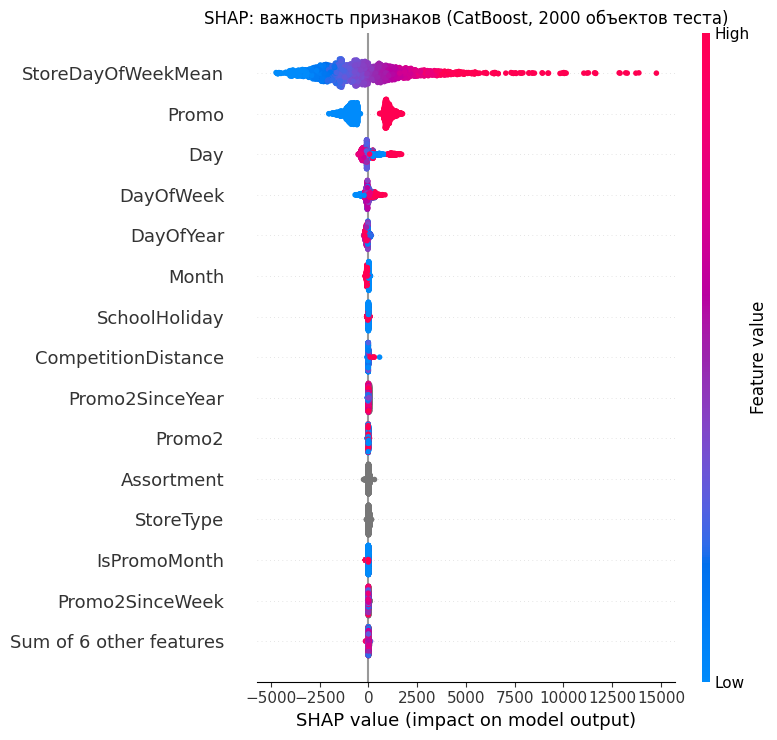

In [ ]:
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title('SHAP: важность признаков (CatBoost, 2000 объектов теста)')
plt.tight_layout()
plt.show()

8.3. Scatter plot для 3 ключевых признаков

По горизонтали значение признака, по вертикали вклад.
В первом графике заметна линейная зависимость: чем выше продали, тем больше модель добавляет.
Во втором графике: поскольку promo имеет всего два значения, то promo=1 добавляет, а promo=0 отнимает.
Третий график DayOfWeek. Имеет 7 значений и небольшие вклады.

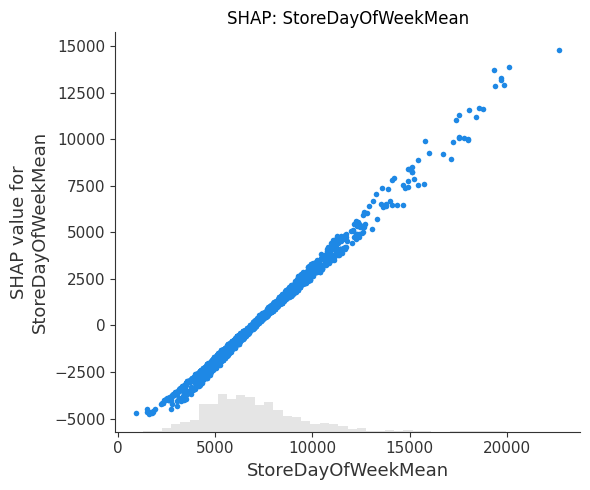

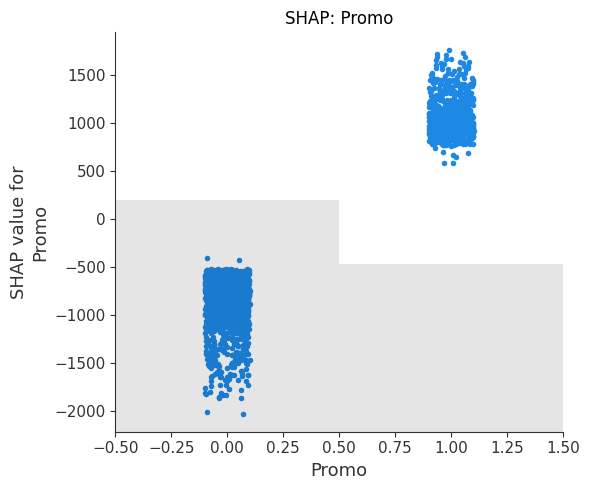

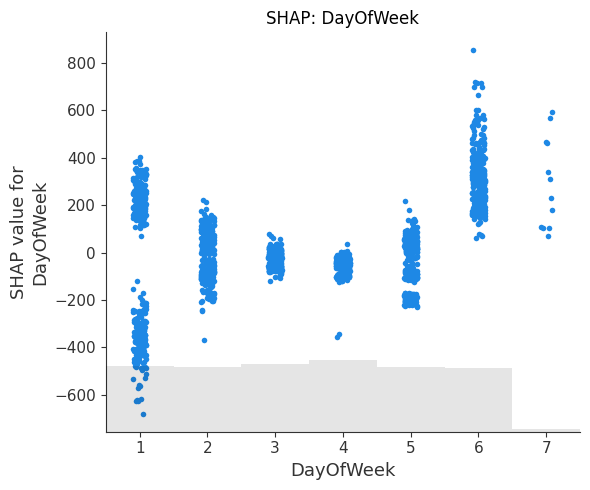

In [ ]:
explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(len(shap_values), base_value),
    data=X_expl.values,
    feature_names=X_expl.columns.tolist(),
)

# Scatter — как вклад зависит от значения признака
top_features = ['StoreDayOfWeekMean', 'Promo', 'DayOfWeek']

for feat in top_features:
    if feat in X_expl.columns:
        shap.plots.scatter(
            explanation[:, feat],
            show=False,
        )
        plt.title(f'SHAP: {feat}')
        plt.tight_layout()
        plt.show()
    else:
        print(f'{feat} нет в X_expl — пропускаем')

8.4. waterfall (тоже через explanation).

Разбирает три конкретных прогноза, где модель угадала, занизила и завысила. Красные значения увеличивают прогноз, синие уменьшают. Длина полосы означает размер вклада. Стартовая точка расположена внизу и изменяется в зависимости от влияний, в то время как верхняя точка является итоговым прогнозом.


 Точный прогноз
y_true = 7101, pred = 7101, resid = -0


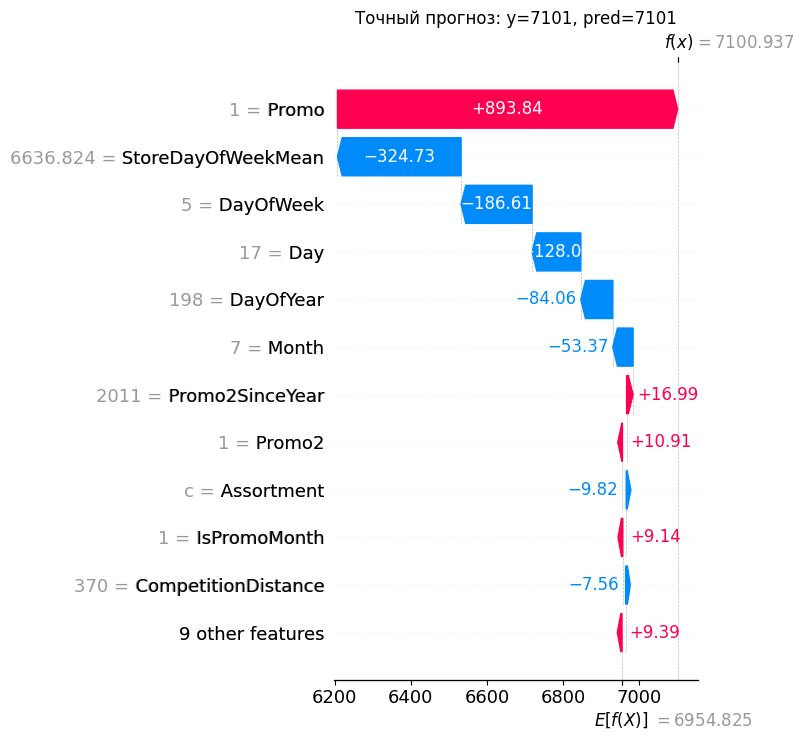


 Недопрогноз
y_true = 9605, pred = 14285, resid = +4680


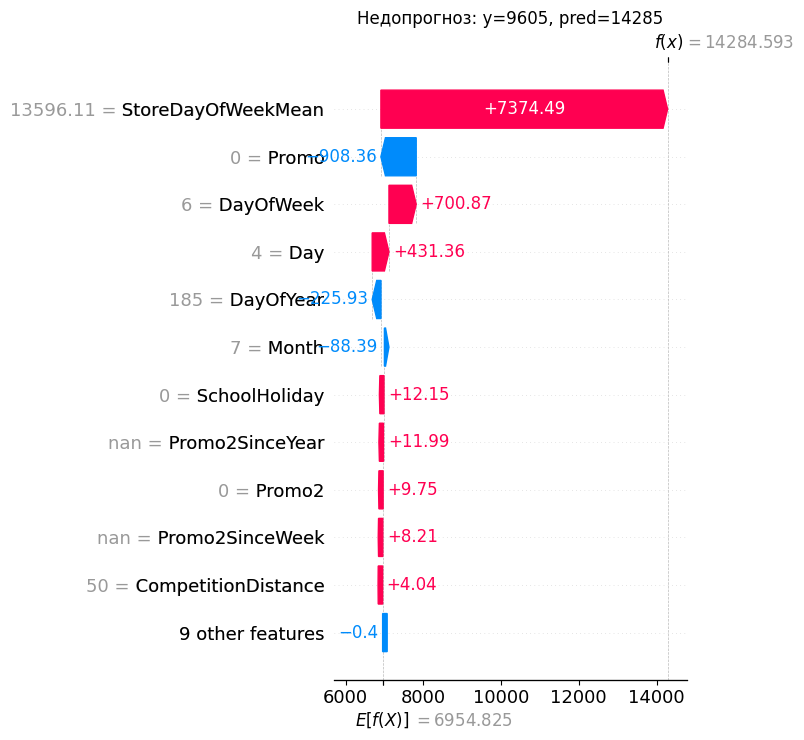


 Перепрогноз
y_true = 41551, pred = 9141, resid = -32410


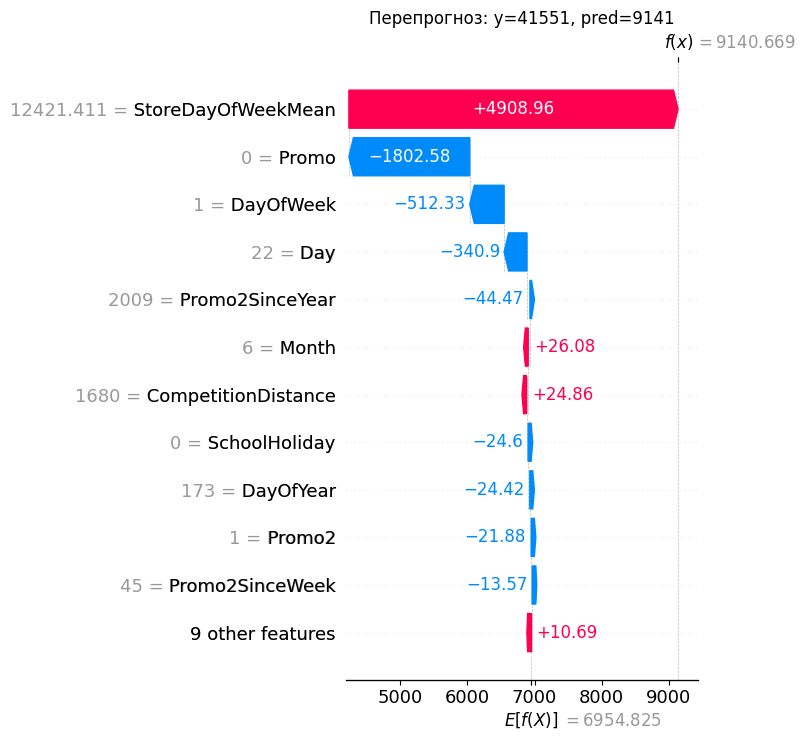

In [ ]:
pred_expl = final_cb.predict(X_expl)
y_expl = y_test.loc[X_expl.index].values
resid = pred_expl - y_expl
abs_resid = np.abs(resid)

idx_best = np.argmin(abs_resid)
idx_under = np.argmax(resid)
idx_over = np.argmin(resid)

for label, idx in [('Точный прогноз', idx_best),
                   ('Недопрогноз', idx_under),
                   ('Перепрогноз', idx_over)]:
    print(f'\n {label}')
    print(f'y_true = {y_expl[idx]:.0f}, pred = {pred_expl[idx]:.0f}, resid = {resid[idx]:+.0f}')
    shap.plots.waterfall(explanation[idx], max_display=12, show=False)
    plt.title(f'{label}: y={y_expl[idx]:.0f}, pred={pred_expl[idx]:.0f}')
    plt.tight_layout()
    plt.show()

## Шаг 8. Интерпретация модели (SHAP)

Модель: CatBoost (RMSPE = 0.1423 на тесте).
Выборка для SHAP: 2000 объектов теста.

### Глобальная важность (beeswarm)

| Ранг | Признак | Разброс SHAP | Комментарий |
|---|---|---|---|
| 1 | **StoreDayOfWeekMean** | от −1000 до +3000 | доминирует |
| 2 | **Promo** | ±1500 (два кластера) | чёткое разделение |
| 3 | Day | ±300 | небольшой |
| 4 | DayOfWeek | ±300 | небольшой |
| 5 | DayOfYear | ±200 | небольшой |
| 6–20 | остальные | ±100 | шум |

Наблюдения:
- Модель сильно опирается на StoreDayOfWeekMean -- продажи магазина в конкретный день недели.
- Promo является вторым признаком.
- Все остальные признаки на уровне шума (меньше 5% от прогноза).


### Выводы для заказчика

1. Прогноз основан на истории магазина. Модель смотрит в первую очередь на продажи магазина в этот день недели. Качество прогноза зависит от наличия достаточной истории по каждому магазину. Новые магазины будут прогнозироваться хуже.
2. Промо-акции хорошо влияют. Промо поднимает прогноз на ~900 единиц (≈13% от среднего). Если промо не запланировано, модель это учитывает и дает меньший прогноз.
3. Остальные признаки слабо влияют на прогноз. День месяца, месяц, праздники, расстояние до конкурента дают очень маленький вклад от прогноза.
4.Ограничения SHAP. SHAP показывает поведение модели, а не причинно-следственные связи.
5. Практическая рекомендация. Для повышения качества прогноза стоит фокусироваться на:
   * количестве истории продаж по каждому магазину;
   * точном планировании промо акций;

##Шаг 9. Сохранение модели.

Задание:
> *	Соберите финальный пайплайн «признаки + модель» и сохраните его вместе с порогом. Если порог подбирался для откалиброванной модели, сохраняйте откалиброванную.
*	Сформируйте input_schema.json с описанием входных признаков.
*	Проверьте, что загруженная модель даёт те же прогнозы, а ноутбук выполняется целиком после перезапуска ядра.



Ячейка 9.1. Сохраняем справочники

store_dow_mean_table -- таблица средних продаж по (Store, DayOfWeek).

sales_median_train -- медиана продаж на train.

Обе сохраним в model.joblib.

In [ ]:
# 1. Справочник средних продаж по (Store, DayOfWeek) — на train
store_dow_mean_table = (
    df_train.groupby(['Store', 'DayOfWeek'])['Sales']
    .mean()
    .rename('StoreDayOfWeekMean')
    .reset_index()
)
print('store_dow_mean_table:', store_dow_mean_table.shape)

# 2. Медиана Sales на train -- для заполнения пропусков
sales_median_train = float(df_train['Sales'].median())
print('sales_median_train:', sales_median_train)

store_dow_mean_table: (6723, 3)
sales_median_train: 6368.0


9.2. Функция полного пайплайна predict_pipeline



In [ ]:
def predict_pipeline(df_input, bundle):
    """
    Полный пайплайн: сырой df → признаки → прогноз.

    Параметры:
    ----------
    df_input : pd.DataFrame
        Должен содержать столбцы: Store, DayOfWeek, Date, Promo, StateHoliday,
        SchoolHoliday, StoreType, Assortment, CompetitionDistance,
        CompetitionOpenSinceMonth, CompetitionOpenSinceYear, Promo2,
        Promo2SinceWeek, Promo2SinceYear, PromoInterval, Open
        (столбцы Customers и Sales — необязательны, игнорируются).

    bundle : dict
        Загруженный model.joblib.

    Возвращает:
    -----------
    np.ndarray — прогнозы Sales.
    """
    X = df_input.copy()

    # 1. Оставляем только строки Open=1. Используется только в неотфильтрованных данных, поэтому убрано под комментарий. Если open нет -- вызовет ошибку
    # X = X[X['Open'] == 1].copy()

    # 2. Удаляем Sales и Customers, если есть
    X = X.drop(columns=['Sales', 'Customers'], errors='ignore')
    # 3. Добавляем StoreDayOfWeekMean (из справочника)
    X = X.merge(bundle['store_dow_mean'], on=['Store', 'DayOfWeek'], how='left')
    X['StoreDayOfWeekMean'] = X['StoreDayOfWeekMean'].fillna(bundle['sales_median'])
    # 4. Добавляем date + competition признаки
    X = bundle['add_features'](X)
    # 5. Убираем Date
    X = X.drop(columns=['Date'], errors='ignore')
    # 6. Приводим категориальные к строке (для CatBoost)
    # заполняем NaN на 'missing' (как в обучении), потом переводим в str. Иначе NaN превращается в строку 'nan', что не использовалось в обучении.
    for c in bundle['cat_cols']:
        if c in X.columns:
            X[c] = X[c].astype(object).fillna('missing').astype(str)

    # 7. Выравниваем порядок столбцов по тому, на чём обучалась модель
    X = X[bundle['feature_names']]
    # 8. Прогноз
    return bundle['model'].predict(X)

9.3. Собираем bundle и сохраняем.


joblib — библиотека для сериализации Python-объектов.
Быстрее для больших numpy-массивов, компактнее, умеет сохранять sklearn-модели и pandas-DataFrame.

In [ ]:
import joblib
import json
import datetime as dt

bundle = {
    'model': final_cb,
    'cat_cols': cat_cols,
    'feature_names': X_train_cb.columns.tolist(),
    'store_dow_mean': store_dow_mean_table,
    'sales_median': sales_median_train,
    'add_features': add_features,
    'metadata': {
        'version': '1.0',
        'created_at': dt.datetime.now().isoformat(timespec='seconds'),
        'rmspe_test': float(rmspe_cb_test),
        'threshold_alpha': 2/3,  # для квантильной
        'notes': 'CatBoost (best RMSPE), лаг 42 исключён по абляции',
    },
}

joblib.dump(bundle, 'model.joblib')
print('model.joblib сохранён')
print(f'Размер: {os.path.getsize("model.joblib") / 1024 / 1024:.2f} МБ')

model.joblib сохранён
Размер: 0.54 МБ


9.4. Проверка воспроизводимости.

Загружаем словарь, примеяем к сырым df_test, проверяем наличие разницы. Поскольку float-числа не всегда совпадают, к примеру, из-за разных платформ, используется allclose.


In [ ]:
# Загружаем обратно
bundle_loaded = joblib.load('model.joblib')
# Применяем к сырому df_test
pred_pipeline = predict_pipeline(df_test, bundle_loaded)
# Сравниваем с оригиналом
original_pred = final_cb.predict(X_test_cb)

diff = np.abs(pred_pipeline - original_pred)
print('Проверка воспроизводимости')
print(f'Максимальное расхождение: {diff.max():.6f}')
print(f'Среднее расхождение: {diff.mean():.6f}')
print(f'Совпадают ли прогнозы: {np.allclose(pred_pipeline, original_pred, atol=1e-6)}')

assert np.allclose(pred_pipeline, original_pred, atol=1e-6), \
    'Прогнозы не совпадают!'
print('Прогноз совпадает!')

Проверка воспроизводимости
Максимальное расхождение: 0.000000
Среднее расхождение: 0.000000
Совпадают ли прогнозы: True
Прогноз совпадает!


Ячейка 9.5. input_schema.json

Создает Json описание входных данных модели. Детально описывает схему данных, типы, минимум и максимум, список уникальных значений. Позволяет избежать введения некорректных данных при дальнейшем использовании.

In [ ]:
def column_schema(s):
    """Описывает один столбец."""
    if pd.api.types.is_numeric_dtype(s):
        return {
            'type': 'number',
            'min': float(s.min()),
            'max': float(s.max()),
        }
    else:
        return {
            'type': 'category',
            'values': sorted(s.dropna().astype(str).unique().tolist()),
        }

# Используем df_test
raw_columns = [
    'Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday',
    'StoreType', 'Assortment', 'CompetitionDistance',
    'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear',
    'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Date',
]
schema = {
    'version': '1.0',
    'created_at': dt.datetime.now().isoformat(timespec='seconds'),
    'model': 'CatBoostRegressor',
    'target': 'Sales',
    'metric': 'RMSPE',
    'required_columns': raw_columns,
    'columns': {col: column_schema(df_test[col]) for col in raw_columns if col in df_test.columns},
}

with open('input_schema.json', 'w', encoding='utf-8') as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)

print('input_schema.json сохранён')
print(f'Колонок в схеме: {len(schema["columns"])}')

input_schema.json сохранён
Колонок в схеме: 16


Ячейка 9.5. Скачиваение

In [ ]:
from google.colab import files

#чтобы скачать
files.download('model.joblib')
files.download('input_schema.json')
files.download('experiments.csv')

print('Скачивание')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Скачивание
